# Validation with HYPERNETS: Sentinel-2 vs TRISHNA bands

## Requirements
- HYPERNETS water reflectance (L2A) of a site (here BEFR, Berre lagoon, from the WATERHYPERNET portal).
- Sentinel-2 L1C subsets around the site (NetCDF, GRSdriver format) and the CAMS files.
- The GRS look-up tables.

## Tutorial objectives
- Convolve the hyperspectral HYPERNETS reflectance with the TRISHNA and Sentinel-2 bands.
- Measure the real S2 -> TRISHNA band differences and the OWT classification on in situ spectra.
- Validate GRS run with TRISHNA-like bands and with all S2 bands on the same matchups.
- Validate the water quality products available with TRISHNA bands.

## Environment
Use the `sandbox_env` kernel of the CNES JupyterHub. Otherwise install the packages below in your environment (the `trishna_tbx` toolbox: `pip install -e <path>/trishna_tbx`):

`GRSdriver`, `grs`, `GRSl2bgen`, `radcalnet_oc`, `invRrs`, `trishna_tbx`, `matplotlib`, `pandas`, `xarray`.

## Resources
The code can be executed with the CPU: 4 cores, 8 GB. Run time: ~1 h the first time (GRS on all matchups), then < 2 min.

![version](https://img.shields.io/badge/version-11.2026-blue)

## Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import trishna_tbx
from trishna_tbx import TRISHNA, make_s2
print('trishna_tbx', trishna_tbx.__version__)
from pathlib import Path
THUMB_DIR = Path('../thumbnails').resolve() if Path('../thumbnails').exists() else Path('.').resolve()
plt.rcParams.update({'figure.dpi': 90, 'font.size': 11})

from trishna_tbx import algorithms, owt
from trishna_tbx.validation import (load_hypernets, convolve, find_matchups, process_matchup, metrics,
                                    find_l2a, extract_l2a_window)
from trishna_tbx.emulate import owt_band_adjustment
from pyproj import Transformer

trishna_tbx 0.0.1


## Data
> HYPERNETS data: https://waterhypernet.org (account needed). The L1C subsets can be produced with GRSdriver (`Sentinel2Driver(..., subset=...)` then `prod.to_netcdf`).

In [2]:
import os
from pathlib import Path

# ---- edit here (or set the environment variables) ------------------------------------
HYP_FILE = os.environ.get('TRISHNA_TBX_HYPERNETS', '/DATA/hypernets/BEFR/BEFR_hypernets.nc')  # Berre lagoon
L1C_SUBSET_DIR = os.environ.get('TRISHNA_TBX_L1C_SUBSETS',
                                '/data/satellite/Sentinel-2/subset/hypernets/L1C/BEFR')  # S2 L1C around the site
CAMS_DIR = os.environ.get('TRISHNA_TBX_CAMS_DIR', '/data/cams/world')   # cams_forecast_YYYY-MM.nc
MAX_DT = '1h'           # maximum time difference HYPERNETS - Sentinel-2
HALF_WINDOW = 1         # 3x3 pixels at 60 m around the site
MAX_MATCHUPS = None     # None: all (about 1 h of GRS processing the first time, then cached)
# optional reference: archived standard GRS L2A (all bands, 20 m) of the same acquisitions (None to skip)
L2A_ARCHIVE_DIR = os.environ.get('TRISHNA_TBX_L2A_ARCHIVE', '/data/satellite/Sentinel-2/subset/hypernets/L2A_v221/BEFR')
OUTPUT_DIR = Path(os.environ.get('TRISHNA_TBX_OUTPUT', './output')).resolve()
# ---------------------------------------------------------------------------------------
CACHE_DIR = OUTPUT_DIR / 'hypernets_matchups'
CACHE_DIR.mkdir(parents=True, exist_ok=True)

> This tutorial extends *Validation L2A* (Validation section) to the TRISHNA bands.

## 1. HYPERNETS at the Berre lagoon
HYPERNETS measures the water-leaving reflectance every 30 min from a fixed platform
(HYPSTAR radiometer, 400-900 nm in the distributed L2A). `Rrs` is the reflectance divided
by pi, with the NIR similarity correction (Ruddick et al. 2006). Basic QC: quality flag 0,
solar zenith angle < 70 deg.

In [3]:
hyp = load_hypernets(HYP_FILE)
site = hyp.attrs['site_id']
lon, lat = hyp.attrs['site_longitude'], hyp.attrs['site_latitude']
site_xy = Transformer.from_crs(4326, 32631, always_xy=True).transform(lon, lat)
print(f'{site}: {hyp.sizes["time"]} records after QC, {str(hyp.time.values[0])[:10]} -> {str(hyp.time.values[-1])[:10]}')
print(f'site: {lat:.4f} N, {lon:.4f} E  ->  UTM 31N {site_xy[0]:.0f}, {site_xy[1]:.0f}')

BEFR: 1665 records after QC, 2021-02-24 -> 2023-02-26
site: 43.4423 N, 5.0972 E  ->  UTM 31N 669708, 4812071


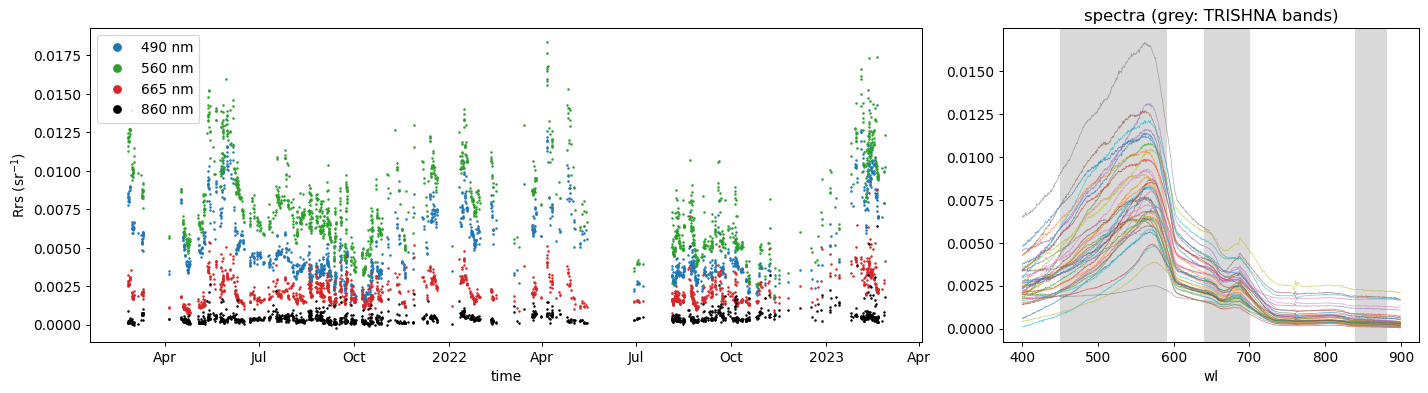

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={'width_ratios': [2, 1]})
for w, c in [(490, 'tab:blue'), (560, 'tab:green'), (665, 'tab:red'), (860, 'k')]:
    hyp.Rrs.sel(wl=w, method='nearest').plot(ax=axs[0], ls='', marker='.', ms=2, c=c, label=f'{w} nm')
axs[0].legend(markerscale=6); axs[0].set_title(''); axs[0].set_ylabel('Rrs (sr$^{-1}$)')
sub = hyp.Rrs.isel(time=slice(None, None, 40))
for i in range(sub.sizes['time']):
    sub.isel(time=i).plot(ax=axs[1], lw=.6, alpha=.6)
for b in TRISHNA.subset(['Blue', 'Green', 'Red', 'NIR']).bands:
    axs[1].axvspan(b.center - b.fwhm / 2, b.center + b.fwhm / 2, color='0.85', zorder=0)
axs[1].set_title('spectra (grey: TRISHNA bands)'); axs[1].set_ylabel('')
fig.tight_layout()
fig.savefig(THUMB_DIR / 'validation_hypernets_trishna.png', dpi=60)

## 2. HYPERNETS seen by TRISHNA and Sentinel-2
The hyperspectral Rrs is band-averaged (weighted by the solar irradiance) with each sensor
response. The ratio TRISHNA / S2 is the **real** band adjustment factor for this site, to be
compared with the factors derived from the Bi et al. (2024) OWT spectra. The TRISHNA WV band
(910 nm) is outside the 400-900 nm range of the data.

In [5]:
s2 = make_s2()
S2W = s2.subset(['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8A'], 'S2')
S2T = s2.subset(['B2', 'B3', 'B4', 'B8A'], 'S2-as-TRISHNA')
TRW = TRISHNA.subset(['Blue', 'Green', 'Red', 'NIR'], 'TRISHNA')
h_s2 = convolve(hyp.Rrs, S2W)
h_tri = convolve(hyp.Rrs, TRW)
pairs = [('Blue', 'B2'), ('Green', 'B3'), ('Red', 'B4'), ('NIR', 'B8A')]
ratio = pd.DataFrame({t: (h_tri.sel(band=t) / h_s2.sel(band=b)).to_pandas() for t, b in pairs})
ratio.describe(percentiles=[.05, .5, .95]).T[['5%', '50%', '95%']].round(3)

,5%,50%,95%
Blue,0.878,0.917,0.950
Green,0.914,0.939,0.964
Red,0.978,1.003,1.056
NIR,1.003,1.014,1.046


In [6]:
# OWT of the in situ spectra (hyperspectral reference classification)
ref, _ = owt.load_reference('Bi2024')
hyp_owt, _ = owt.classify(hyp.Rrs.interp(wl=ref.wl.sel(wl=slice(400, 900))),
                          ref.sel(wl=slice(400, 900)), dim='wl')
# factors predicted from the OWT mean spectra (as used to emulate TRISHNA)
_, _, f_table = owt_band_adjustment(h_s2.sel(band=['B2', 'B3', 'B4', 'B8A'])
                                    .drop_vars('wl').assign_coords(band=[490, 560, 665, 865]).rename(band='wl'), S2T)
obs = ratio.assign(owt=hyp_owt.values).groupby('owt').median()
obs.columns = [490, 560, 665, 865]
cmp = pd.concat({'HYPERNETS (median)': obs, 'OWT model': f_table.loc[obs.index]}, axis=1)
cmp.insert(0, 'N', ratio.assign(owt=hyp_owt.values).groupby('owt').size())
cmp.round(3)

N HYPERNETS (median)                      OWT model                \
                         490    560    665    865       490    560    665   
owt                                                                         
3a      1              1.022  0.964  1.049  1.010     1.009  1.002  0.974   
3b    146              0.932  0.948  0.987  1.015     0.985  1.004  0.983   
4a    129              0.949  0.945  1.025  1.007     0.929  0.966  0.987   
4b   1362              0.914  0.937  1.002  1.015     0.902  0.970  1.003   
5a     25              0.879  0.907  1.094  1.021     0.856  0.939  1.077   
6       2              0.968  0.960  1.035  1.000     0.922  0.973  1.003   

            
       865  
owt         
3a   1.059  
3b   1.066  
4a   1.053  
4b   1.060  
5a   1.064  
6    1.023

## 3. Optical water types from in situ spectra
Real-data version of the benchmark of *Optical water types with TRISHNA bands*: the class
obtained with the full spectrum is the reference.

In [7]:
rows = {}
for sens, conv in [(S2W, h_s2), (TRW, h_tri)]:
    r = owt.convolve_reference(ref, sens)
    cls, _ = owt.classify(conv, r.drop_vars('wl'), dim='band')
    rows[sens.name] = {'10 classes': float((cls.values == hyp_owt.values).mean()),
                       '7 merged classes': float((owt.merge_classes(cls).values == owt.merge_classes(hyp_owt).values).mean())}
print('OWT occurrence (hyperspectral):', hyp_owt.to_series().value_counts().to_dict())
(100 * pd.DataFrame(rows)).round(1)

OWT occurrence (hyperspectral): {'4b': 1362, '3b': 146, '4a': 129, '5a': 25, '6': 2, '3a': 1}


,S2,TRISHNA
10 classes,94.2,93.0
7 merged classes,96.7,95.7


## 4. Matchups with Sentinel-2
S2 L1C subsets with a HYPERNETS record within `MAX_DT`. GRS is run at 60 m on each subset
twice: with the TRISHNA-like bands (aerosol/glint from 865/1610 nm) and with all the S2
bands (1610/2190 nm), with the same GRS version and settings. The median of the valid water
pixels in a 3x3 window (180 m) around the platform is kept. Results are cached in
`CACHE_DIR`.

In [8]:
mu = find_matchups(hyp.time.values, L1C_SUBSET_DIR, MAX_DT)
if MAX_MATCHUPS:
    mu = mu.iloc[:MAX_MATCHUPS]
print(len(mu), 'matchups within', MAX_DT)

80 matchups within 1h


In [9]:
%%time
res = []
for i, row in mu.iterrows():
    r = process_matchup(row.l1c, CAMS_DIR, CACHE_DIR, site_xy, half=HALF_WINDOW)
    if r is not None:
        res.append(r.expand_dims(matchup=[i]))
sat = xr.concat(res, 'matchup', join='outer')
print(f'{sat.sizes["matchup"]} matchups processed')

79 matchups processed
CPU times: user 3.8 s, sys: 267 ms, total: 4.07 s
Wall time: 4.34 s


Reference: the archived standard GRS products (GRS v2.2.1, all bands, native 20 m, 180 m window)
of the same acquisitions, to check that the 60 m processing used here does not degrade the
results.

In [10]:
if L2A_ARCHIVE_DIR and Path(L2A_ARCHIVE_DIR).exists():
    arch = []
    for i in sat.matchup.values:
        f = find_l2a(L2A_ARCHIVE_DIR, mu.loc[i, 's2_time'])
        if f:
            arch.append(extract_l2a_window(f, site_xy, half_m=90, name='S2 archive (20 m)').expand_dims(matchup=[i]))
    print(f'{len(arch)} archived products found')
    sat = xr.concat([sat.reset_coords(drop=True), xr.concat(arch, 'matchup').reset_coords(drop=True)], 'bandset', join='outer')
BANDSETS = list(sat.bandset.values)
print(BANDSETS)

79 archived products found
['TRISHNA', 'S2', 'S2 archive (20 m)']


In [11]:
# in situ values at the matchup times, quality screening of the satellite windows
hm = mu.loc[sat.matchup.values]
ins_s2 = h_s2.sel(time=hm.hyp_time.values).assign_coords(time=sat.matchup.values).rename(time='matchup')
ins_tri = h_tri.sel(time=hm.hyp_time.values).assign_coords(time=sat.matchup.values).rename(time='matchup')
cv560 = sat.Rrs_std.sel(wl=560) / sat.Rrs.sel(wl=560)
good = (sat.n_valid >= 5).all('bandset') & (cv560 < 0.2).all('bandset') & sat.Rrs.sel(wl=560).notnull().all('bandset')
good = good.drop_vars('wl', errors='ignore')
print(f'{int(good.sum())} matchups kept (>= 5 valid water pixels, CV(560) < 20 %)')
sat_g, s2_g, tri_g = sat.sel(matchup=good), ins_s2.sel(matchup=good), ins_tri.sel(matchup=good)

64 matchups kept (>= 5 valid water pixels, CV(560) < 20 %)


## 5. Rrs validation
All GRS runs use the same S2 measurements: they are compared with HYPERNETS convolved with
the **S2** responses. Differences between the `S2` and `TRISHNA` rows come only from the
atmospheric correction band set (aerosol/glint bands); the last row is the archived reference.

,,N,bias,MdAPD (%),RMSD,slope,intercept,r
TRISHNA,490,64.0,-0.00202,43.35261,0.00288,0.55785,0.00022,0.66062
S2,490,64.0,-0.00081,30.00278,0.00224,0.79935,0.00090,0.66651
S2 archive (20 m),490,64.0,-0.00024,15.13764,0.00159,0.70556,0.00129,0.78016
TRISHNA,560,64.0,-0.00241,34.68789,0.00303,0.60168,0.00045,0.79191
S2,560,64.0,-0.00111,22.60897,0.00207,0.72485,0.00133,0.74617
S2 archive (20 m),560,64.0,-0.00073,14.72411,0.00173,0.68163,0.00153,0.83785
TRISHNA,665,64.0,-0.00156,62.07946,0.00174,0.65905,-0.00069,0.64731
S2,665,64.0,-0.00047,38.92914,0.00137,0.80737,0.00054,0.51582
S2 archive (20 m),665,64.0,-0.00014,21.92412,0.00097,0.69726,0.00069,0.60680
TRISHNA,865,64.0,-0.00026,77.09035,0.00062,0.03895,0.00024,0.03544


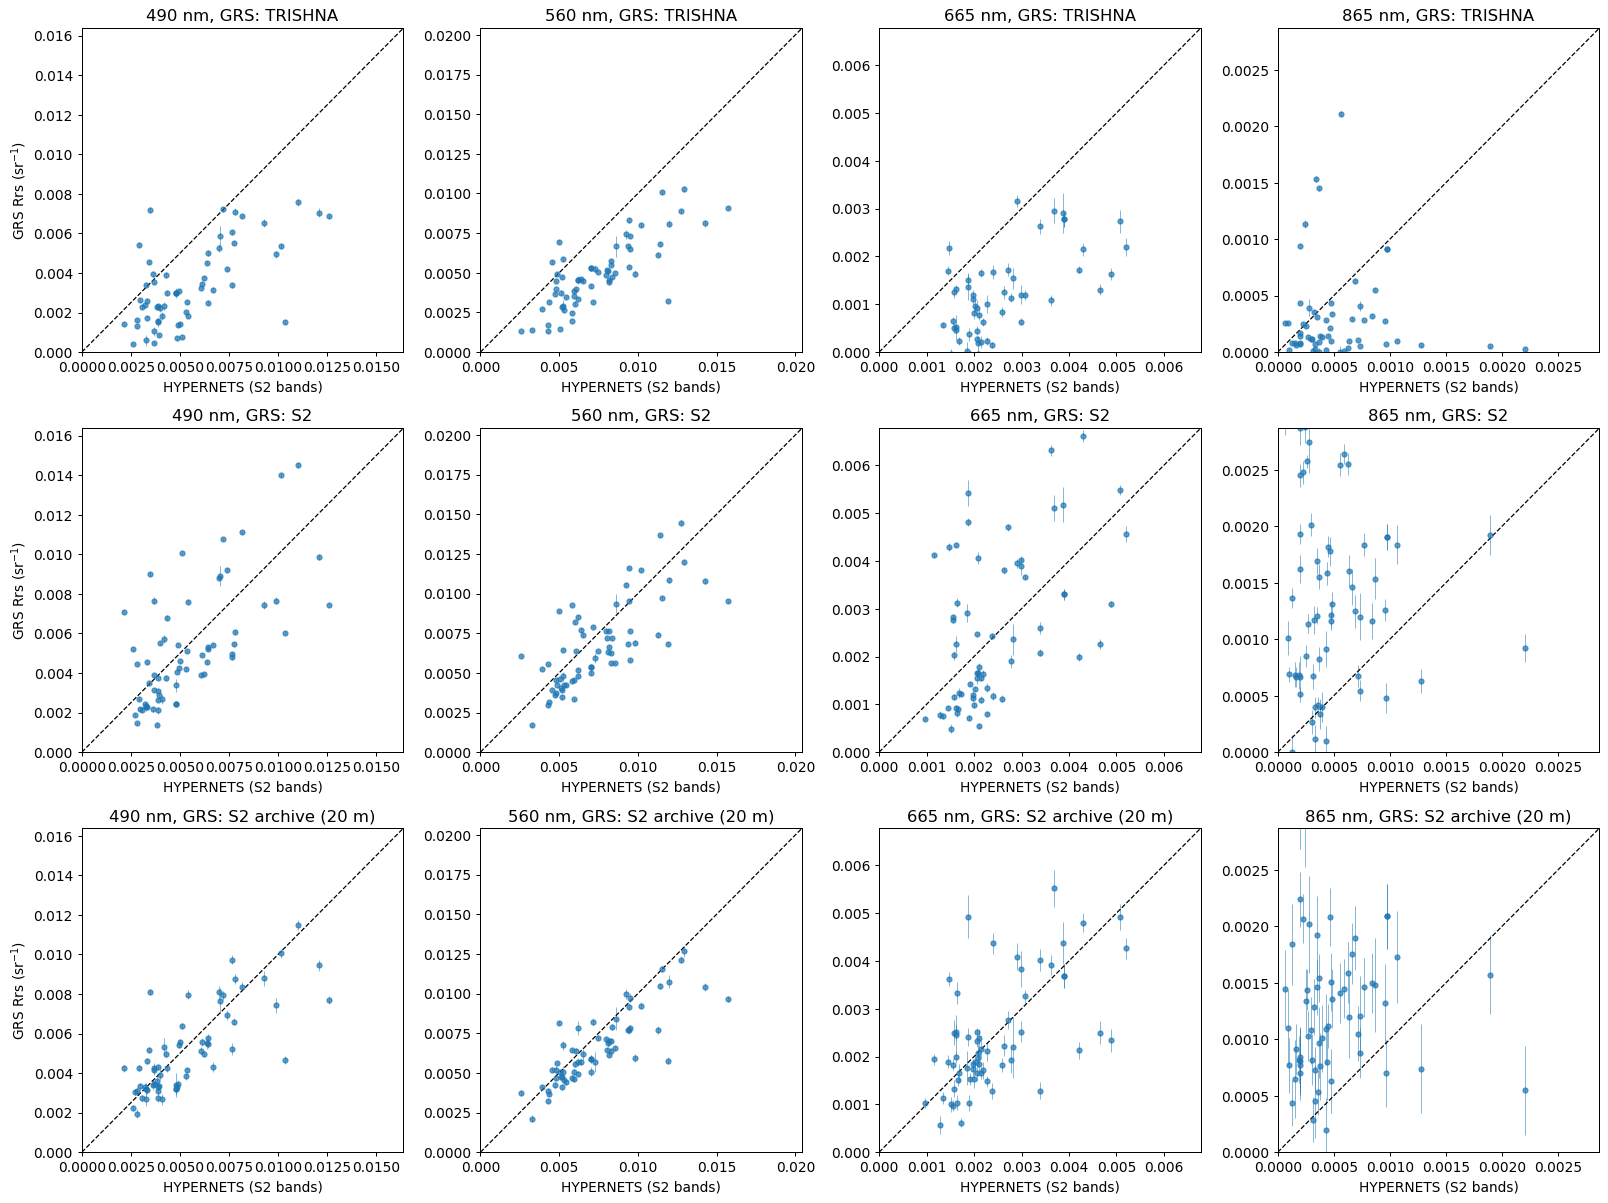

In [12]:
wls = [(490, 'B2'), (560, 'B3'), (665, 'B4'), (865, 'B8A')]
fig, axs = plt.subplots(len(BANDSETS), 4, figsize=(18, 4.5 * len(BANDSETS)), squeeze=False)
stats = {}
for j, (w, b) in enumerate(wls):
    x = s2_g.sel(band=b).values
    lim = [min(0, np.nanmin(x)), 1.3 * np.nanmax(x)]
    for i, bs in enumerate(BANDSETS):
        y = sat_g.Rrs.sel(bandset=bs, wl=w).values
        ax = axs[i, j]
        ax.errorbar(x, y, yerr=sat_g.Rrs_std.sel(bandset=bs, wl=w).values, fmt='o', ms=4, alpha=.7, lw=.6)
        ax.plot(lim, lim, 'k--', lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
        ax.set_title(f'{w} nm, GRS: {bs}'); ax.set_xlabel('HYPERNETS (S2 bands)')
        stats[(bs, w)] = metrics(x, y)
for ax in axs[:, 0]:
    ax.set_ylabel('GRS Rrs (sr$^{-1}$)')
fig.tight_layout()
pd.DataFrame(stats).T.round(5)

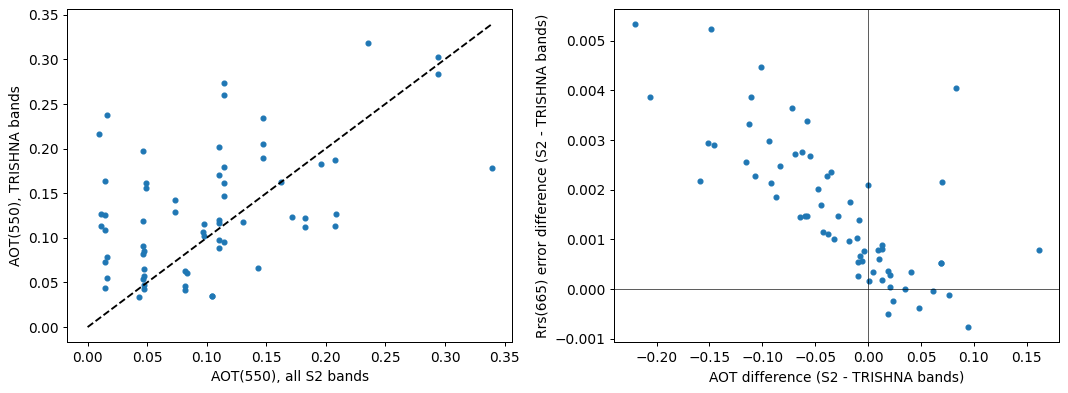

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
axs[0].scatter(sat_g.aot550.sel(bandset='S2'), sat_g.aot550.sel(bandset='TRISHNA'), s=15)
m = float(sat_g.aot550.max()); axs[0].plot([0, m], [0, m], 'k--')
axs[0].set_xlabel('AOT(550), all S2 bands'); axs[0].set_ylabel('AOT(550), TRISHNA bands')
err = {bs: (sat_g.Rrs.sel(bandset=bs, wl=665) - s2_g.sel(band='B4')).values for bs in ['S2', 'TRISHNA']}
axs[1].scatter(sat_g.aot550.sel(bandset='S2') - sat_g.aot550.sel(bandset='TRISHNA'), err['S2'] - err['TRISHNA'], s=15)
axs[1].axhline(0, c='k', lw=.5); axs[1].axvline(0, c='k', lw=.5)
axs[1].set_xlabel('AOT difference (S2 - TRISHNA bands)'); axs[1].set_ylabel('Rrs(665) error difference (S2 - TRISHNA bands)')
fig.tight_layout()

### What a TRISHNA validation would see
With real TRISHNA data, HYPERNETS would be convolved with the TRISHNA responses. On the
emulated data, the GRS-TRISHNA Rrs (S2 bands) is converted to TRISHNA bands with the OWT-dependent
factors, then compared with HYPERNETS convolved with the TRISHNA responses.

In [14]:
rt = sat_g.Rrs.sel(bandset='TRISHNA', wl=[490, 560, 665, 865]).transpose('wl', 'matchup')
rt_adj, _, _ = owt_band_adjustment(rt, S2T)
stats_t = {}
for (w, _), t in zip(wls, ['Blue', 'Green', 'Red', 'NIR']):
    stats_t[(t, 'S2 bands (no adjustment)')] = metrics(tri_g.sel(band=t).values, rt.sel(wl=w).values)
    stats_t[(t, 'OWT band adjustment')] = metrics(tri_g.sel(band=t).values, rt_adj.sel(wl=w).values)
pd.DataFrame(stats_t).T[['N', 'bias', 'MdAPD (%)', 'r']].round(4)

N    bias  MdAPD (%)       r
Blue  S2 bands (no adjustment)  64.0 -0.0017    39.0407  0.6613
      OWT band adjustment       64.0 -0.0020    43.3531  0.6589
Green S2 bands (no adjustment)  64.0 -0.0020    30.7479  0.7876
      OWT band adjustment       64.0 -0.0021    32.3633  0.7888
Red   S2 bands (no adjustment)  64.0 -0.0016    62.3397  0.6537
      OWT band adjustment       64.0 -0.0016    60.9438  0.6548
NIR   S2 bands (no adjustment)  64.0 -0.0003    77.3544  0.0346
      OWT band adjustment       64.0 -0.0003    76.0061  0.0355

## 6. Water quality products
Products computed from HYPERNETS (S2 bands) and from GRS with both band sets, for the
algorithms available with TRISHNA bands.

In [15]:
def products(rrs_band, names):
    r = rrs_band.sel(band=names).drop_vars('wl').assign_coords(band=[490, 560, 665, 865]).rename(band='wl')
    return algorithms.run_all(r.transpose('wl', ...), S2T)

p_ins = products(s2_g, ['B2', 'B3', 'B4', 'B8A'])
p_sat = {bs: algorithms.run_all(sat_g.Rrs.sel(bandset=bs, wl=[490, 560, 665, 865]).transpose('wl', ...), S2T)
         for bs in BANDSETS}
rows = {}
for v in ['SPM_Nechad10', 'TUR_Dogliotti15', 'Kd490_KD2', 'Kd_par_RD22', 'Chla_OC2']:
    for bs in BANDSETS:
        rows[(v, f'GRS {bs}')] = metrics(p_ins[v].values, p_sat[bs][v].values)
pd.DataFrame(rows).T[['N', 'bias', 'MdAPD (%)', 'slope', 'r']].round(3)

N   bias  MdAPD (%)  slope      r
SPM_Nechad10    GRS TRISHNA            64.0 -1.815     63.211  0.610  0.646
                GRS S2                 64.0 -0.564     40.627  0.809  0.515
                GRS S2 archive (20 m)  64.0 -0.164     22.795  0.691  0.604
TUR_Dogliotti15 GRS TRISHNA            64.0 -1.166     63.272  0.608  0.646
                GRS S2                 64.0 -0.363     40.698  0.809  0.515
                GRS S2 archive (20 m)  64.0 -0.105     22.840  0.691  0.604
Kd490_KD2       GRS TRISHNA            57.0  0.054     31.060  4.431  0.324
                GRS S2                 64.0 -0.010     23.106  1.055  0.353
                GRS S2 archive (20 m)  64.0 -0.031     19.919  0.965  0.547
Kd_par_RD22     GRS TRISHNA            64.0  0.146      7.070  0.698  0.777
                GRS S2                 64.0  0.062      7.037  0.833  0.781
                GRS S2 archive (20 m)  64.0  0.005      4.012  0.806  0.834
Chla_OC2        GRS TRISHNA            56.0  0.764     34.931  2.341  0.188
                GRS S2                 64.0 -0.135     26.771  1.067  0.334
                GRS S2 archive (20 m)  64.0 -0.434     22.839  0.973  0.536

## Take-home messages
With the default data (HYPERNETS BEFR, Berre lagoon, 2021-2023: 80 S2 matchups within 1 h,
64 kept after screening):
- **In situ band differences**: TRISHNA / S2 ratios of the in situ Rrs are ~0.92 (Blue), ~0.94
  (Green), ~1.00 (Red), ~1.01 (NIR). The OWT-based model used to emulate TRISHNA reproduces Blue and
  Red within ~1 %, but is off by 3-5 % for Green and NIR: use site data such as HYPERNETS when available.
- **OWT on real spectra**: TRISHNA bands give the hyperspectral class in ~93 % of the cases (S2: ~94 %),
  much better than the synthetic benchmark: real spectra at one site are less variable than the
  synthetic members.
- **Atmospheric correction**: with the same GRS version and settings, the TRISHNA band set
  (aerosol/glint from 865/1610 nm) has a larger negative bias than the S2 band set
  (1610/2190 nm): about -0.002 sr-1 in the visible, MdAPD 35-60 % vs 23-40 %, with similar
  correlations. The AOT figure shows why: the matchups where the 865/1610 pair retrieves a
  higher AOT than the SWIR pair are those with the most negative Rrs error. In these moderately
  turbid waters the 865 nm water signal is not zero and is partly taken as aerosol
  (over-correction): a TRISHNA processing needs a NIR water-signal correction (similarity
  spectrum, iterative scheme) or a stronger weight on 1610 nm.
- **Processing setup**: the archived standard GRS products (20 m, GRS v2.2.1) perform about
  twice better (MdAPD 15-22 %) than the 60 m re-processing used here for both band sets: the
  TRISHNA vs S2 comparison is fair, but absolute errors are pessimistic.
- **Band adjustment** changes the TRISHNA validation statistics by only a few %: the atmospheric
  correction error dominates.
- **Products**: SPM / turbidity inherit the visible/red bias (MdAPD ~63 % with TRISHNA bands,
  ~41 % with S2 bands, ~23 % archive); Kd_PAR (Roy & Das) is robust (~7 %); Kd490 and OC2 are poor
  at this site with all band sets.
- The 865 nm Rrs is not validated (no skill for any band set) and the TRISHNA WV band (910 nm) is
  outside the distributed HYPERNETS range.

## References
- HYPERNETS / WATERHYPERNET: https://waterhypernet.org, processor https://hypernets-processor.readthedocs.io
- Ruddick, K. et al. (2006), Seaborne measurements of near infrared water-leaving reflectance: the similarity spectrum, L&O 51.
- Harmel, T. et al. (2018), Sunglint correction of the MSI-SENTINEL-2 imagery over inland and sea waters from SWIR bands, RSE 204.